# Clasificación de microestructuras bainíticas
## Vision Transformer (ViT)

## 1. Instalar las librerías

In [1]:
# Instalar transformers
!pip install -q transformers

## 2. Importar librerías y conectar con Google Drive

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import ViTImageProcessor, ViTForImageClassification

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

from google.colab import drive
drive.mount('/content/drive')

# Semillas (incluye GPU) para que los resultados sean más reproducibles
semilla = 42
random.seed(semilla)
np.random.seed(semilla)
torch.manual_seed(semilla)
torch.cuda.manual_seed_all(semilla)

dispositivo = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', dispositivo)

Mounted at /content/drive
Dispositivo: cuda


## 3. Cargar las rutas y revisar las imágenes

In [3]:
ruta = '/content/drive/MyDrive/Proyecto IA2-20261024T175559Z-1-001/Proyecto IA2/Bainitic Microstructures'
ruta_train = os.path.join(ruta, 'im_train')
ruta_test = os.path.join(ruta, 'testset')

clases = ['i', 'ii', 'iii']

In [4]:
# Contar las imágenes por clase
for clase in clases:
    n_train = len(os.listdir(os.path.join(ruta_train, clase)))
    n_test = len(os.listdir(os.path.join(ruta_test, clase)))
    print(f'Clase {clase}: train = {n_train}, test = {n_test}')

Clase i: train = 316, test = 198
Clase ii: train = 310, test = 102
Clase iii: train = 306, test = 86


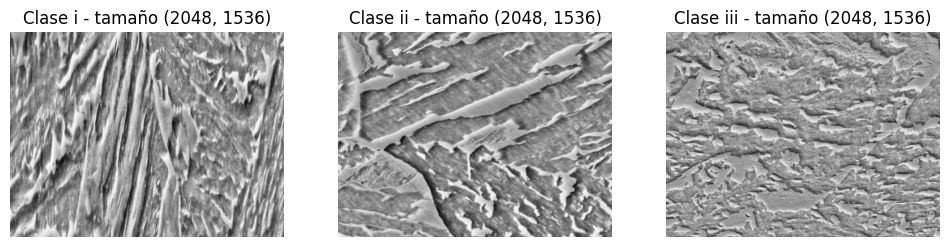

In [5]:
# Un ejemplo por clase.
plt.figure(figsize=(12, 4))

for i, clase in enumerate(clases):
    carpeta = os.path.join(ruta_train, clase)
    archivo = next(nombre for nombre in os.listdir(carpeta)
                   if nombre.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')))
    imagen = Image.open(os.path.join(carpeta, archivo)).convert('L')

    plt.subplot(1, 3, i + 1)
    plt.imshow(imagen, cmap='gray')
    plt.title(f'Clase {clase} - tamaño {imagen.size}')
    plt.axis('off')

plt.show()

## 4. Preparar las rutas y las etiquetas

In [6]:
# Tablay división estratificada de im_train en train/validación.
# testset queda aparte para la evaluación final
extensiones = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')
etiquetas = {'i': 0, 'ii': 1, 'iii': 2}

def crear_tabla(carpeta):
    datos = []
    for clase in clases:
        carpeta_clase = os.path.join(carpeta, clase)
        for archivo in sorted(os.listdir(carpeta_clase)):
            if archivo.lower().endswith(extensiones):
                datos.append([
                    os.path.join(carpeta_clase, archivo),
                    clase,
                    etiquetas[clase]
                ])
    return pd.DataFrame(datos, columns=['ruta', 'clase', 'label'])

df = crear_tabla(ruta_train)
test_df = crear_tabla(ruta_test)

train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=semilla, stratify=df['label']
)

print('Imágenes de entrenamiento:', len(train_df))
print('Imágenes de validación:', len(val_df))
print('Imágenes de prueba:', len(test_df))

Imágenes de entrenamiento: 745
Imágenes de validación: 187
Imágenes de prueba: 386


## 5. Preparar las imágenes

In [7]:
nombre_modelo = 'google/vit-base-patch16-224-in21k'
procesador = ViTImageProcessor.from_pretrained(nombre_modelo)

class DatasetMicrografias(Dataset):
    def __init__(self, tabla, augment=False):
        self.tabla = tabla.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.tabla)

    def __getitem__(self, indice):
        fila = self.tabla.iloc[indice]
        imagen = Image.open(fila['ruta']).convert('L').convert('RGB')

        if self.augment:
            if random.random() < 0.5:
                imagen = imagen.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            if random.random() < 0.5:
                imagen = imagen.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

        imagen = procesador(images=imagen, return_tensors='pt')['pixel_values'].squeeze(0)
        return imagen, int(fila['label'])

train_ds = DatasetMicrografias(train_df, augment=True)
val_ds = DatasetMicrografias(val_df)
test_ds = DatasetMicrografias(test_df)

lote = 8 if torch.cuda.is_available() else 2
generador = torch.Generator().manual_seed(semilla)   # orden reproducible del barajado
train_loader = DataLoader(train_ds, batch_size=lote, shuffle=True, generator=generador)
val_loader = DataLoader(val_ds, batch_size=lote, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=lote, shuffle=False)

print('Datos preparados.')

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Datos preparados.


## 6. Crear el modelo Vision Transformer

In [8]:
modelo = ViTForImageClassification.from_pretrained(
    nombre_modelo,
    num_labels=3,
    id2label={0: 'i', 1: 'ii', 2: 'iii'},
    label2id={'i': 0, 'ii': 1, 'iii': 2},
    ignore_mismatched_sizes=True,
    attn_implementation='eager'
)

modelo = modelo.to(dispositivo)

# Pesos de clase calculados solo con train
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=train_df['label']
)
pesos = torch.tensor(pesos, dtype=torch.float32).to(dispositivo)
print('Pesos por clase:', pesos)

optimizador = torch.optim.AdamW(modelo.parameters(), lr=2e-5)

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pesos por clase: tensor([0.9854, 1.0013, 1.0136], device='cuda:0')


## 7. Entrenar el modelo

In [9]:
epocas = 10
historial = []
mejor_val_loss = float('inf')
mejor_epoca = None
mejor_pesos = None

for epoca in range(epocas):
    modelo.train()
    perdida_train = 0
    aciertos_train = 0

    for imagenes, etiquetas_lote in tqdm(train_loader, desc=f"Época {epoca+1}/{epocas} - Entrenamiento"):
        imagenes = imagenes.to(dispositivo)
        etiquetas_lote = etiquetas_lote.to(dispositivo)

        optimizador.zero_grad()
        salida = modelo(pixel_values=imagenes).logits
        perdida = torch.nn.functional.cross_entropy(salida, etiquetas_lote, weight=pesos)
        perdida.backward()
        optimizador.step()

        perdida_train += perdida.item() * len(etiquetas_lote)
        aciertos_train += (salida.argmax(1) == etiquetas_lote).sum().item()

    perdida_train /= len(train_ds)
    acc_train = aciertos_train / len(train_ds)

    # Validación
    modelo.eval()
    perdida_val = 0
    aciertos_val = 0

    with torch.no_grad():
        for imagenes, etiquetas_lote in tqdm(val_loader, desc=f"Época {epoca+1}/{epocas} - Validación"):
            imagenes = imagenes.to(dispositivo)
            etiquetas_lote = etiquetas_lote.to(dispositivo)

            salida = modelo(pixel_values=imagenes).logits
            perdida = torch.nn.functional.cross_entropy(salida, etiquetas_lote, weight=pesos)

            perdida_val += perdida.item() * len(etiquetas_lote)
            aciertos_val += (salida.argmax(1) == etiquetas_lote).sum().item()

    perdida_val /= len(val_ds)
    acc_val = aciertos_val / len(val_ds)

    historial.append([perdida_train, perdida_val, acc_train, acc_val])

    print(f'Época {epoca+1}/{epocas} - '
          f'loss: {perdida_train:.4f} - acc: {acc_train:.4f} - '
          f'val_loss: {perdida_val:.4f} - val_acc: {acc_val:.4f}')

    if perdida_val < mejor_val_loss:
        mejor_val_loss = perdida_val
        mejor_epoca = epoca + 1
        mejor_pesos = {k: v.cpu().clone() for k, v in modelo.state_dict().items()}

# Recuperar los mejores pesos
modelo.load_state_dict(mejor_pesos)
modelo.to(dispositivo)

historial = np.array(historial)
print(f'\nMejor época: {mejor_epoca} | menor val_loss: {mejor_val_loss:.4f}')

Época 1/10 - Entrenamiento:   0%|          | 0/94 [00:00<?, ?it/s]

Época 1/10 - Validación:   0%|          | 0/24 [00:00<?, ?it/s]

Época 1/10 - loss: 0.6549 - acc: 0.8362 - val_loss: 0.3213 - val_acc: 0.9251


Época 2/10 - Entrenamiento:   0%|          | 0/94 [00:00<?, ?it/s]

Época 2/10 - Validación:   0%|          | 0/24 [00:00<?, ?it/s]

Época 2/10 - loss: 0.2034 - acc: 0.9705 - val_loss: 0.1133 - val_acc: 1.0000


... (20 outputs left out)

Época 9/10 - loss: 0.0248 - acc: 0.9987 - val_loss: 0.0228 - val_acc: 1.0000


Época 10/10 - Entrenamiento:   0%|          | 0/94 [00:00<?, ?it/s]

Época 10/10 - Validación:   0%|          | 0/24 [00:00<?, ?it/s]

Época 10/10 - loss: 0.0193 - acc: 1.0000 - val_loss: 0.0196 - val_acc: 1.0000

Mejor época: 10 | menor val_loss: 0.0196


## 8. Graficar el entrenamiento

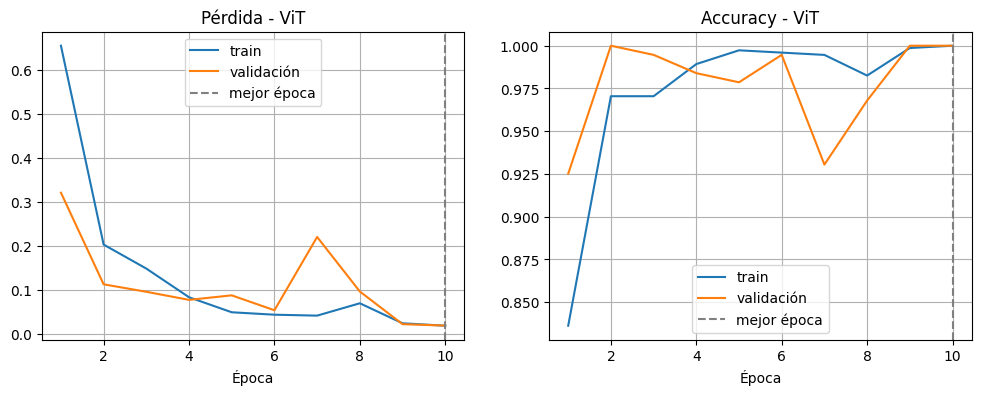

In [10]:
# Curvas de pérdida y accuracy
eje = range(1, len(historial) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(eje, historial[:, 0], label='train')
plt.plot(eje, historial[:, 1], label='validación')
plt.axvline(mejor_epoca, color='gray', linestyle='--', label='mejor época')
plt.title('Pérdida - ViT')
plt.xlabel('Época')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(eje, historial[:, 2], label='train')
plt.plot(eje, historial[:, 3], label='validación')
plt.axvline(mejor_epoca, color='gray', linestyle='--', label='mejor época')
plt.title('Accuracy - ViT')
plt.xlabel('Época')
plt.legend()
plt.grid(True)

plt.show()

## 9. Evaluar con el conjunto de prueba

Accuracy en test: 97.67%

              precision    recall  f1-score   support

           i     0.9659    1.0000    0.9826       198
          ii     0.9895    0.9216    0.9543       102
         iii     0.9884    0.9884    0.9884        86

    accuracy                         0.9767       386
   macro avg     0.9812    0.9700    0.9751       386
weighted avg     0.9771    0.9767    0.9764       386



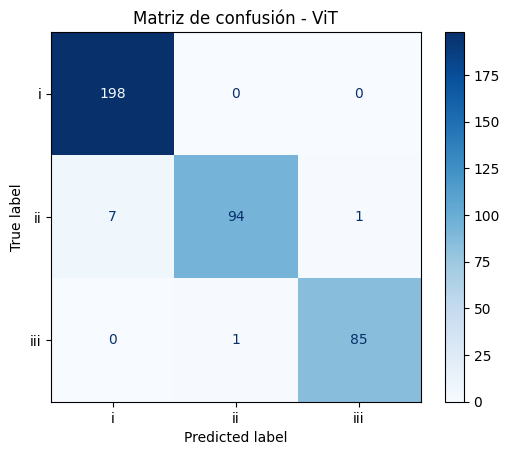

In [11]:
# Evaluación final sobre testset
# 0 = i, 1 = ii, 2 = iii
modelo.eval()
y_real = []
y_pred = []

with torch.no_grad():
    for imagenes, etiquetas_lote in test_loader:
        imagenes = imagenes.to(dispositivo)
        salida = modelo(pixel_values=imagenes).logits
        predicciones = salida.argmax(1).cpu().numpy()

        y_real.extend(etiquetas_lote.numpy())
        y_pred.extend(predicciones)

print(f'Accuracy en test: {accuracy_score(y_real, y_pred) * 100:.2f}%\n')
print(classification_report(
    y_real, y_pred, labels=[0, 1, 2], target_names=clases, digits=4, zero_division=0
))

matriz = confusion_matrix(y_real, y_pred, labels=[0, 1, 2])
grafica = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=clases)
grafica.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - ViT')
plt.show()

## 10. Visualizar las representaciones internas del Transformer

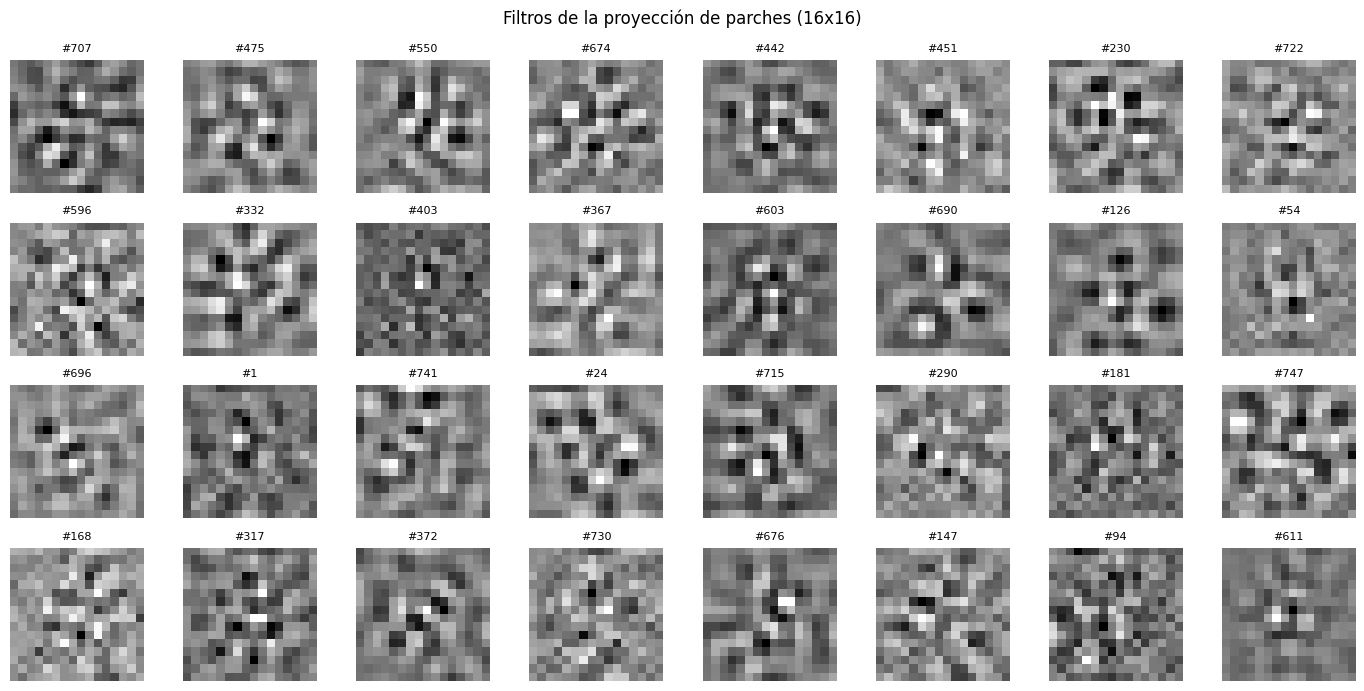

In [12]:
# Filtros de la proyección de parches (primera capa)

W = modelo.vit.embeddings.patch_embeddings.projection.weight.detach().cpu().numpy()   # (768, 3, 16, 16)
Wg = W.sum(axis=1)
orden = np.argsort(np.linalg.norm(Wg.reshape(len(Wg), -1), axis=1))[::-1][:32]

plt.figure(figsize=(14, 7))
for k, idx in enumerate(orden):
    f = Wg[idx]
    plt.subplot(4, 8, k + 1)
    plt.imshow((f - f.min()) / (f.max() - f.min() + 1e-8), cmap='gray')
    plt.title(f'#{idx}', fontsize=8)
    plt.axis('off')
plt.suptitle('Filtros de la proyección de parches (16x16)')
plt.tight_layout()
plt.show()

In [13]:
tam_img = procesador.size['height']
GRID = modelo.config.image_size // modelo.config.patch_size
capas_interes = [1, 4, 8, 12]                                    # bloques a inspeccionar (de 12)

def pasada_interna(ruta_imagen):
    imagen = Image.open(ruta_imagen).convert('L').convert('RGB')
    entrada = procesador(images=imagen, return_tensors='pt')['pixel_values'].to(dispositivo)
    modelo.eval()
    with torch.no_grad():
        salida = modelo(pixel_values=entrada, output_attentions=True, output_hidden_states=True)
    prob = torch.softmax(salida.logits, dim=1)[0].cpu().numpy()
    return imagen.resize((tam_img, tam_img)).convert('L'), salida, prob

def atencion_cls(salida, capa):
    a = salida.attentions[capa - 1][0].mean(dim=0)[0, 1:]
    return a.reshape(GRID, GRID).cpu().numpy()

def rollout(salida):
    n = salida.attentions[0].shape[-1]
    res = torch.eye(n, device=salida.attentions[0].device)
    for a in salida.attentions:
        a = a[0].mean(dim=0) + torch.eye(n, device=a.device)
        a = a / a.sum(dim=-1, keepdim=True)
        res = a @ res
    return res[0, 1:].reshape(GRID, GRID).cpu().numpy()

def a_imagen(mapa):
    t = torch.tensor(mapa)[None, None].float()
    t = torch.nn.functional.interpolate(t, size=(tam_img, tam_img), mode='bilinear', align_corners=False)[0, 0].numpy()
    return (t - t.min()) / (t.max() - t.min() + 1e-8)

img_gris, salida, prob = pasada_interna(test_df['ruta'].iloc[0])
print('Clase real:', test_df['clase'].iloc[0], '| predicha:', clases[prob.argmax()], f'({prob.max():.2f})')
for capa in capas_interes:
    print(f'Bloque {capa:2d}:', tuple(salida.hidden_states[capa][0].shape), '(tokens, canales)')

Clase real: i | predicha: i (0.99)
Bloque  1: (197, 768) (tokens, canales)
Bloque  4: (197, 768) (tokens, canales)
Bloque  8: (197, 768) (tokens, canales)
Bloque 12: (197, 768) (tokens, canales)


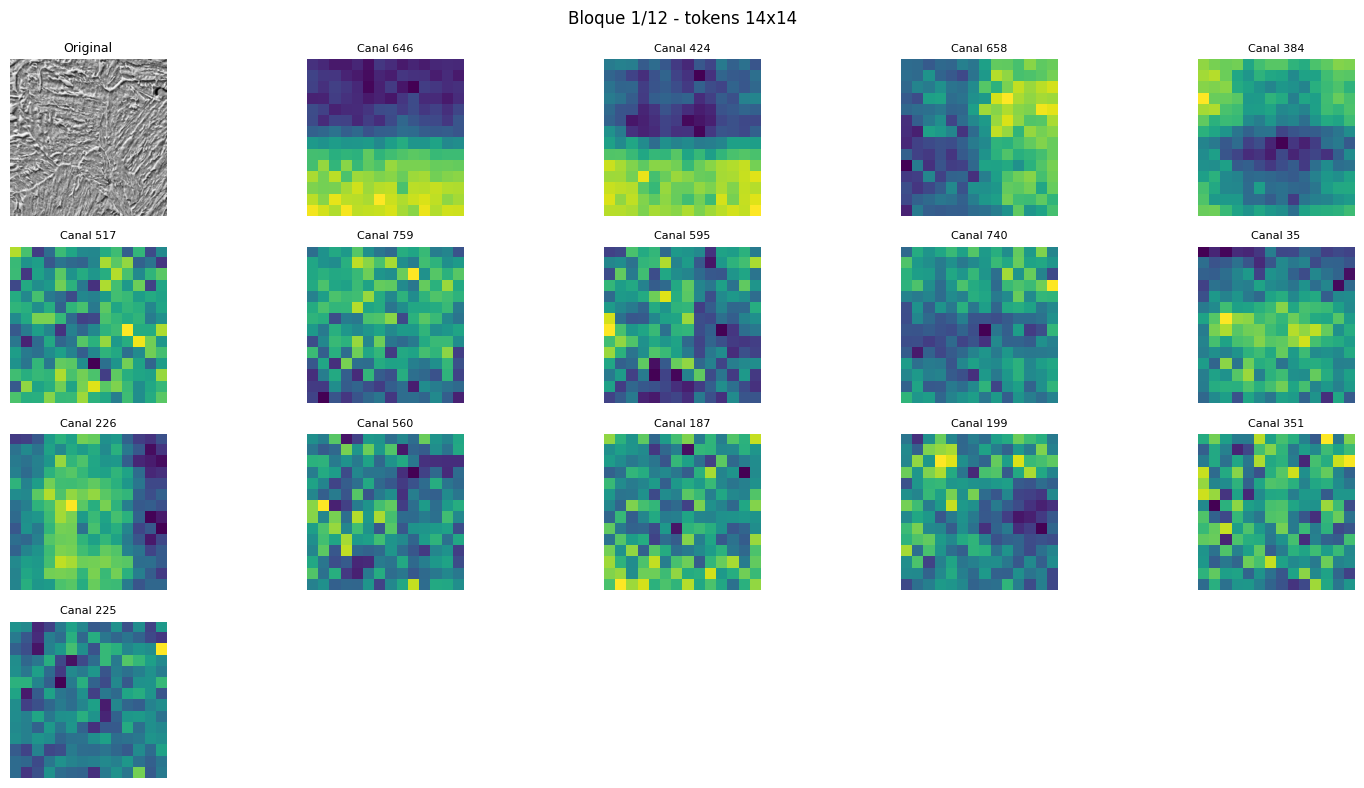

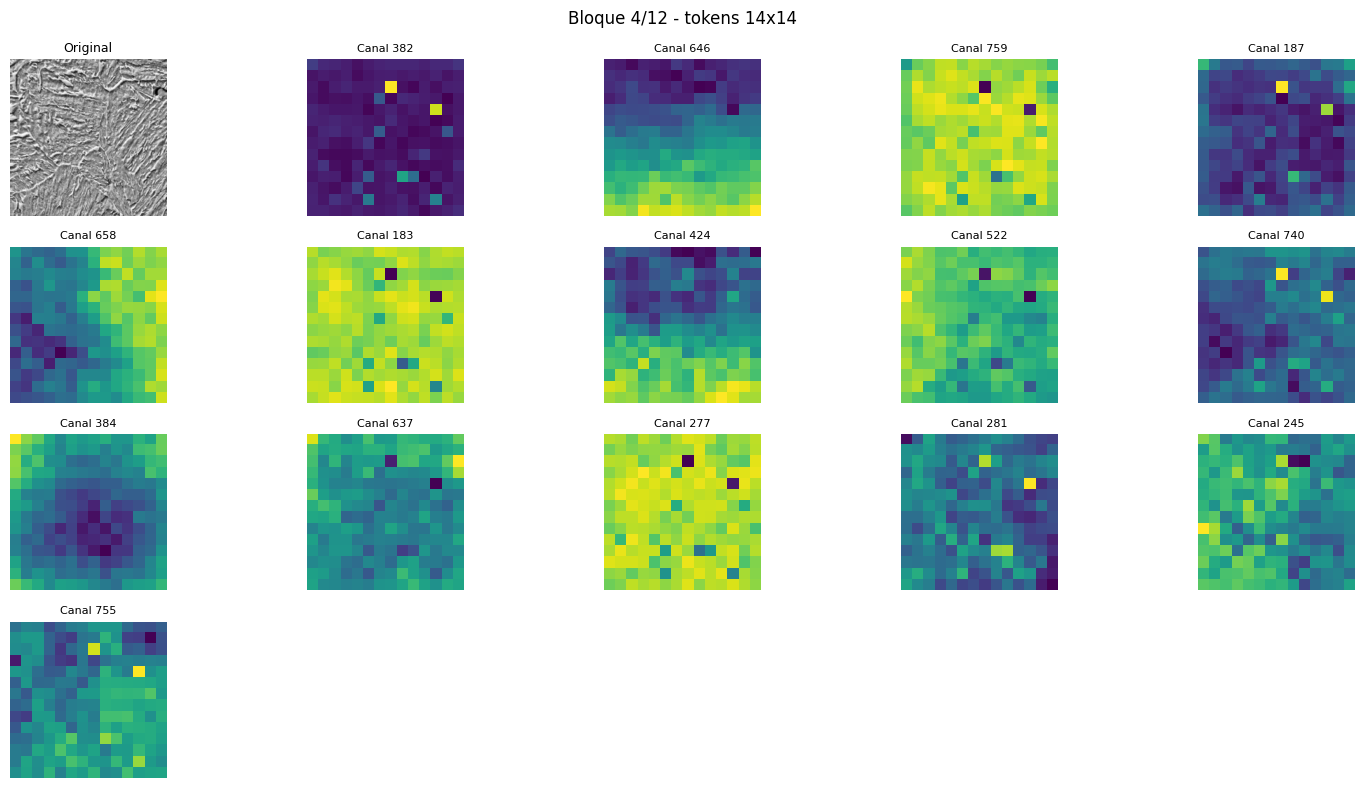

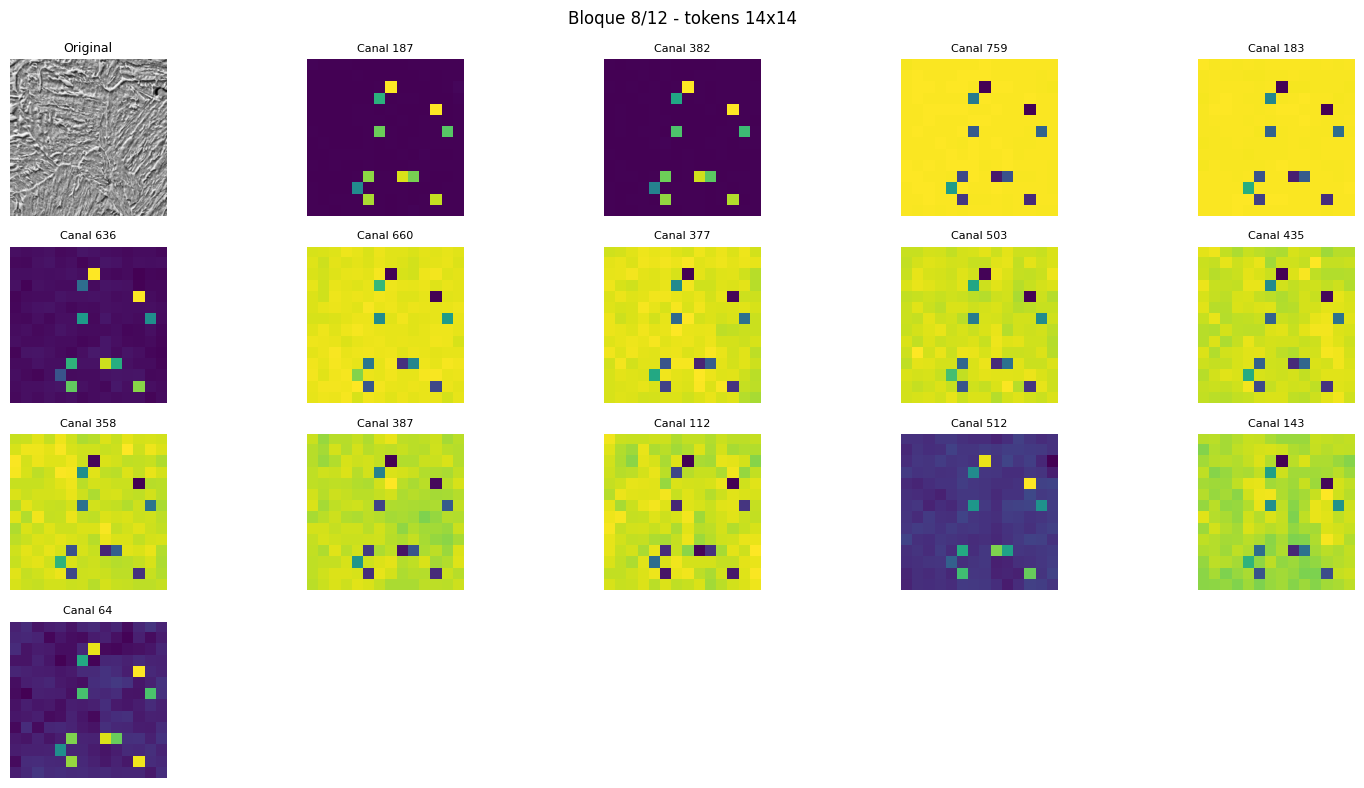

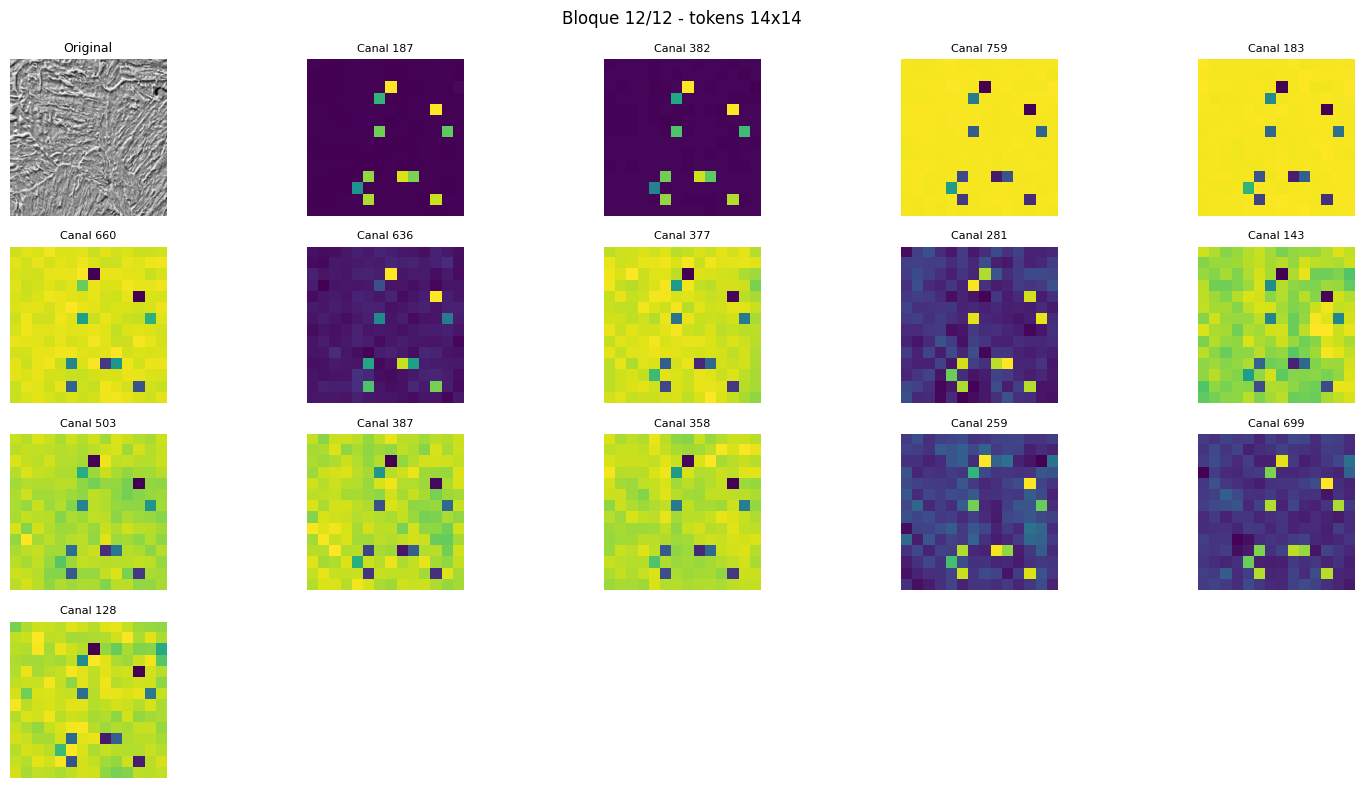

In [14]:
# Features por capa
for capa in capas_interes:
    h = salida.hidden_states[capa][0, 1:, :].cpu().numpy()
    top = np.argsort(h.std(axis=0))[::-1][:15]

    plt.figure(figsize=(15, 8))
    plt.subplot(4, 5, 1)
    plt.imshow(img_gris, cmap='gray')
    plt.title('Original', fontsize=9)
    plt.axis('off')

    for k, c in enumerate(top):
        plt.subplot(4, 5, k + 2)
        plt.imshow(h[:, c].reshape(GRID, GRID), cmap='viridis', interpolation='nearest')
        plt.title(f'Canal {c}', fontsize=8)
        plt.axis('off')

    plt.suptitle(f'Bloque {capa}/12 - tokens {GRID}x{GRID}')
    plt.tight_layout()
    plt.show()

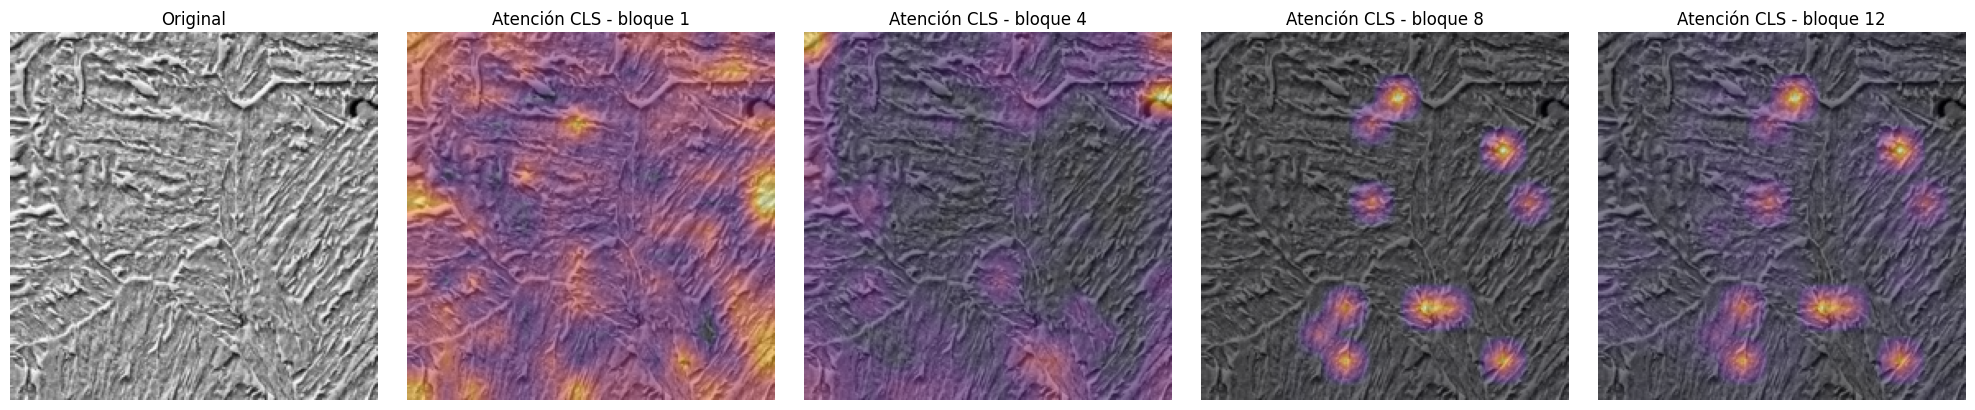

In [15]:
# Atención del token CLS en distintos bloques
plt.figure(figsize=(4 * (len(capas_interes) + 1), 4))

plt.subplot(1, len(capas_interes) + 1, 1)
plt.imshow(img_gris, cmap='gray')
plt.title('Original')
plt.axis('off')

for k, capa in enumerate(capas_interes):
    plt.subplot(1, len(capas_interes) + 1, k + 2)
    plt.imshow(img_gris, cmap='gray')
    plt.imshow(a_imagen(atencion_cls(salida, capa)), cmap='inferno', alpha=0.5)
    plt.title(f'Atención CLS - bloque {capa}')
    plt.axis('off')

plt.tight_layout()
plt.show()

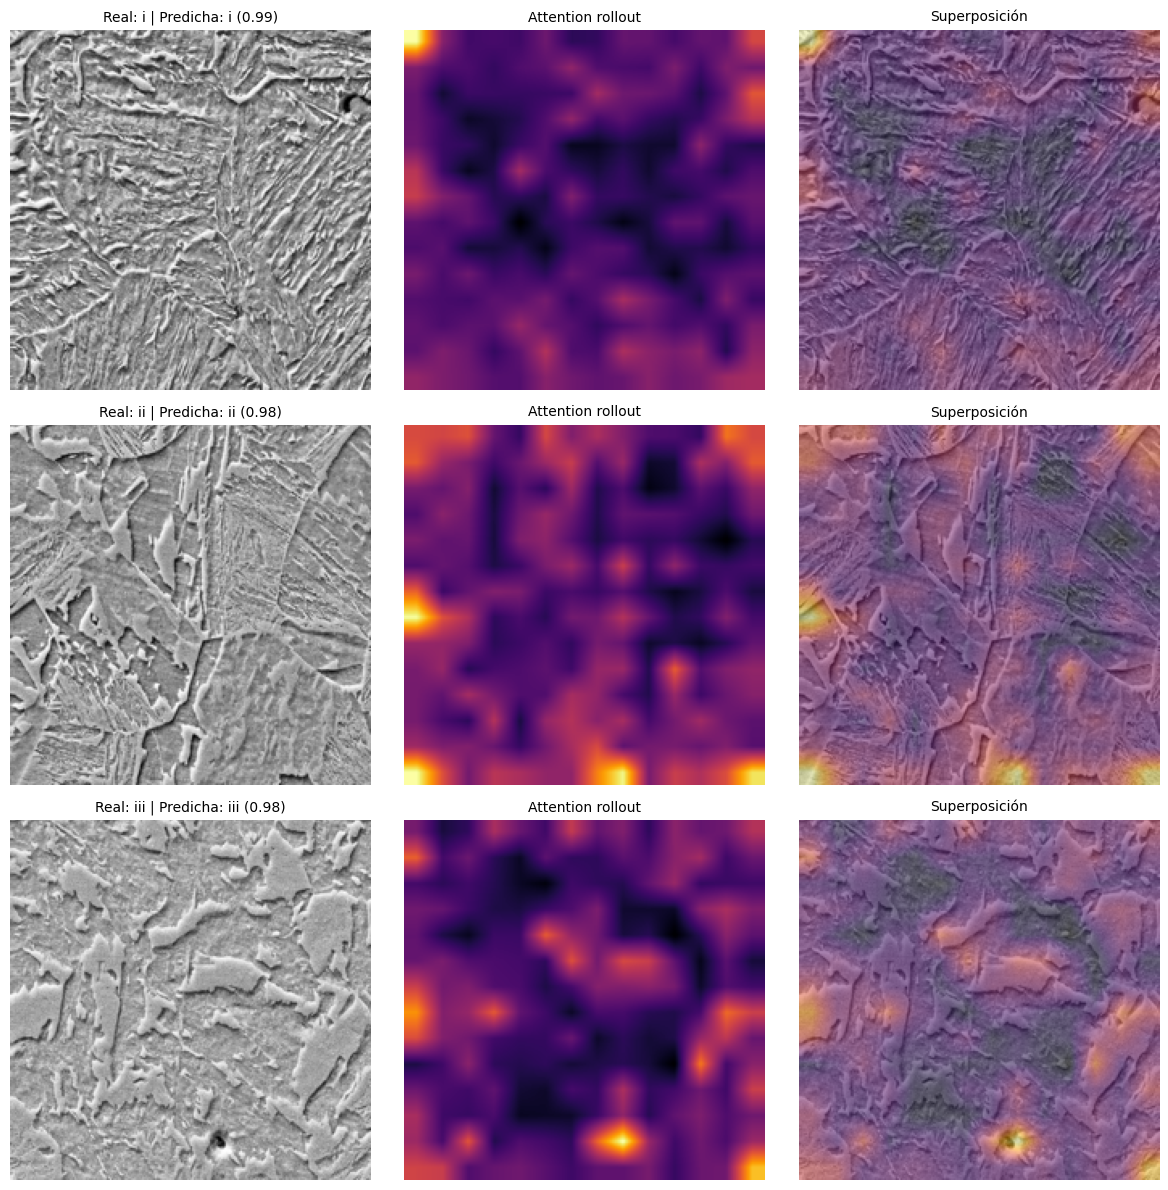

In [16]:
# Attention rollout: un ejemplo de cada clase del testset
plt.figure(figsize=(12, 4 * len(clases)))

for f, clase in enumerate(clases):
    ruta_img = test_df[test_df['clase'] == clase]['ruta'].iloc[0]
    img_g, sal, pr = pasada_interna(ruta_img)
    mapa = a_imagen(rollout(sal))

    plt.subplot(len(clases), 3, f * 3 + 1)
    plt.imshow(img_g, cmap='gray')
    plt.title(f'Real: {clase} | Predicha: {clases[pr.argmax()]} ({pr.max():.2f})', fontsize=10)
    plt.axis('off')

    plt.subplot(len(clases), 3, f * 3 + 2)
    plt.imshow(mapa, cmap='inferno')
    plt.title('Attention rollout', fontsize=10)
    plt.axis('off')

    plt.subplot(len(clases), 3, f * 3 + 3)
    plt.imshow(img_g, cmap='gray')
    plt.imshow(mapa, cmap='inferno', alpha=0.5)
    plt.title('Superposición', fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

## 11. Guardar el modelo

In [ ]:
carpeta_modelo = os.path.join(ruta, 'modelo_vit_entrenado')
os.makedirs(carpeta_modelo, exist_ok=True)

modelo.save_pretrained(carpeta_modelo)
procesador.save_pretrained(carpeta_modelo)

pd.DataFrame(
    historial,
    columns=['loss_train', 'loss_val', 'accuracy_train', 'accuracy_val']
).to_csv(os.path.join(carpeta_modelo, 'historial.csv'), index=False)

print('Modelo guardado en:', carpeta_modelo)